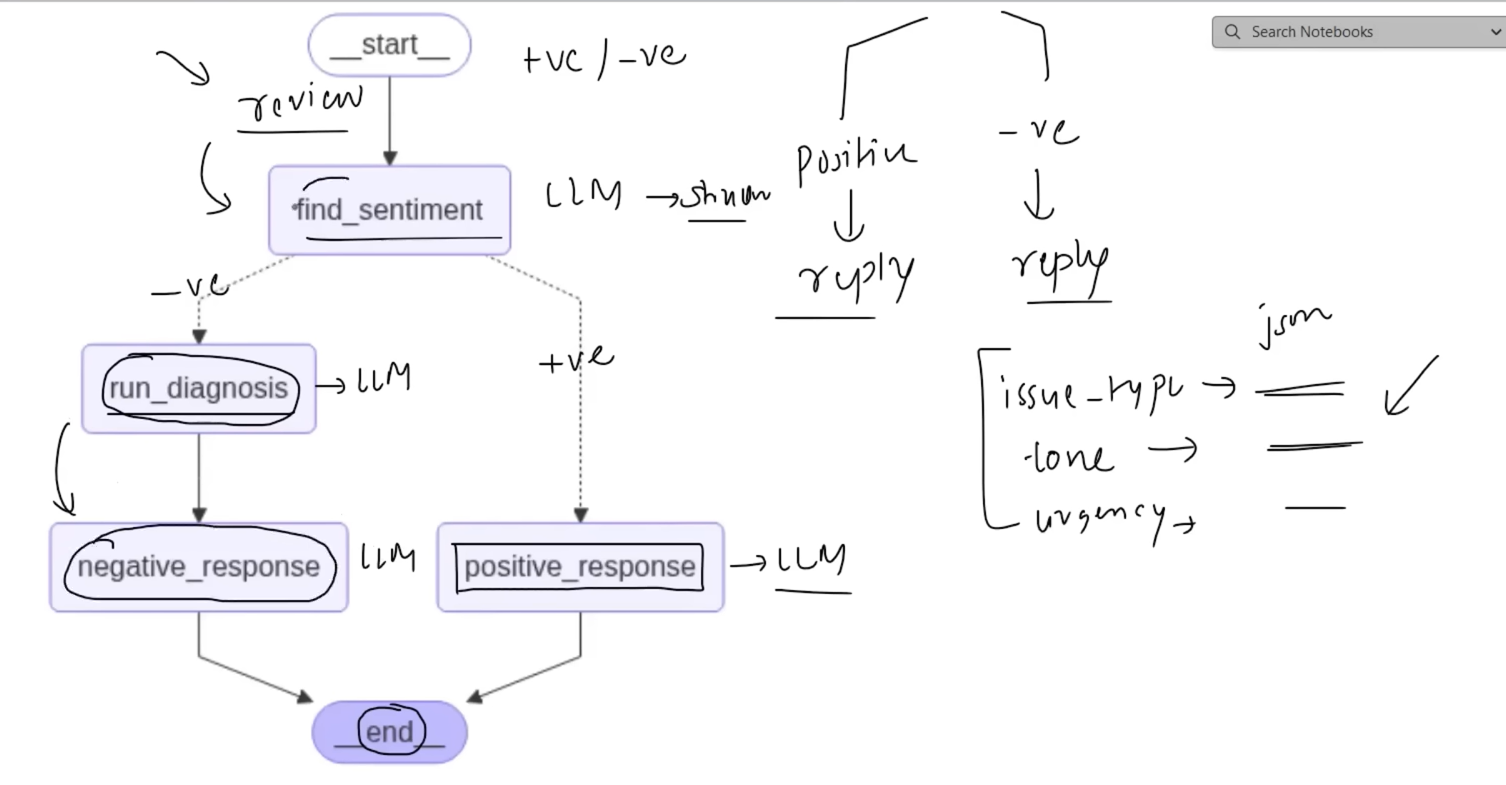

In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field

In [2]:
load_dotenv()

True

In [3]:
model = ChatGroq(model='openai/gpt-oss-120b')

In [11]:
# state mae pehlae review hoga joo user dega 
# then hmm llm sae sentiment analysis krwaynegae 
# -ve hae to analysis krwa kae dict mae store krngae -> then response llm sae
# +ve hae toh seedhae response 

class ReviewState(TypedDict):

    review: str
    sentiment: Literal["positive", "negative"]
    diagnosis: dict
    response: str

Issae 2 values ayengi +ve , -ve jissae pta lgega kahan jana hae 

In [4]:
class SentimentSchema(BaseModel):

    sentiment: Literal["positive", "negative"] = Field(description='Sentiment of the review')

In [5]:
# Agar negative resposne ata hae toh usae dignose krkae btayengae kyn hua 
class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')


In [7]:
structured_model = model.with_structured_output(SentimentSchema)
digonose_structured = model.with_structured_output(DiagnosisSchema)

In [8]:
prompt = 'What is the sentiment of the following review - The software too good'
structured_model.invoke(prompt).sentiment

'positive'

Upper flow is done +ve or -ve review bta rha hae 

<<---------------------------------------------------------------------->>

In [ ]:
# +ve or -ve nikalnae wala function using structured output 
def find_sentiment(state: ReviewState):

    prompt = f'For the following review find out the sentiment \n {state["review"]}'
    sentiment = structured_model.invoke(prompt).sentiment

    return {'sentiment': sentiment}

# decision wala function joo btayega konsi node mae jana hae 
def check_sentiment(state: ReviewState) -> Literal["positive_response", "run_diagnosis"]:

    if state['sentiment'] == 'positive':
        return 'positive_response'
    else:
        return 'run_diagnosis'
    
# yae function +ve reponse generate krwayega 
def positive_response(state: ReviewState):

    prompt = f"""Write a warm thank-you message in response to this review:
    \n\n\"{state['review']}\"\n
Also, kindly ask the user to leave feedback on our website."""
    
    response = model.invoke(prompt).content

    return {'response': response}

# agar negative hae toh pehlae diagnose hoga jo reasone btayega 
# using structured model
def run_diagnosis(state: ReviewState):

    prompt = f"""Diagnose this negative review:\n\n{state['review']}\n"
    "Return issue_type, tone, and urgency.
"""
    response = digonose_structured.invoke(prompt)

    # pydantic object ko json mae dalna 
    return {'diagnosis': response.model_dump()}

# jo dictionary mae json aaya uskae hisab sae response generate krna 
def negative_response(state: ReviewState):

    diagnosis = state['diagnosis']

    prompt = f"""You are a support assistant.
The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.
Write an empathetic, helpful resolution message.
"""
    response = model.invoke(prompt).content

    return {'response': response}
    

In [18]:
graph = StateGraph(ReviewState)

graph.add_node('find_sentiment', find_sentiment)
graph.add_node('positive_response', positive_response)
graph.add_node('run_diagnosis', run_diagnosis)
graph.add_node('negative_response', negative_response)

graph.add_edge(START, 'find_sentiment')

graph.add_conditional_edges('find_sentiment', check_sentiment ,{'positive' : 'positive_response' , 'negative' : 'run_diagnosis'} )

graph.add_edge('positive_response', END)

graph.add_edge('run_diagnosis', 'negative_response')
graph.add_edge('negative_response', END)

workflow = graph.compile()

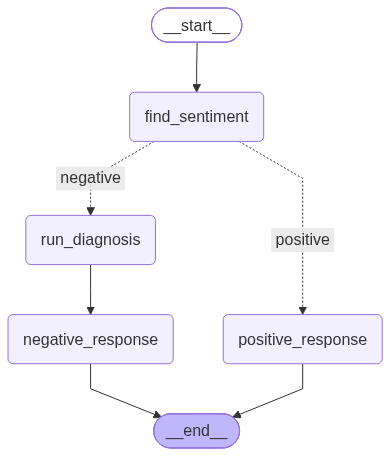

In [19]:
workflow

In [14]:
intial_state={
    'review': "I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality."
}
workflow.invoke(intial_state)

{'review': 'I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality.',
 'sentiment': 'negative',
 'diagnosis': {'issue_type': 'Bug', 'tone': 'angry', 'urgency': 'high'},
 'response': 'Hi\u202f[Customer Name],\n\nI’m really sorry you’re experiencing this bug and understand how frustrating it must be—especially when you need a quick fix. Thank you for letting us know, and I’m treating this as a top‑priority issue.\n\n**What we’ll do right now**\n\n1. **Acknowledge the problem** – I’ve logged a high‑severity ticket (ID\u202f#\u202f[Ticket\u202fNumber]) for our engineering team, and they are already investigating.\n2. **Immediate work‑around** – While we dig deeper, please try the following steps (if you haven’t already):\n   - **Step\u202f1:**\u202f[Clear cache / restart the app / etc.]\n   - **Step\u202f2:**\u202f[Re